# Rainfall Data Analysis and Rainfall Category Classification Using Random Forest

## Project Description

This project focuses on analyzing rainfall data and classifying rainfall conditions into different categories such as **Low, Medium, and High**. The dataset contains important information such as year, month, temperature, humidity, wind speed, pressure, and rainfall measurements. The project first performs data cleaning and preprocessing to handle missing values, duplicate records, invalid values, and inconsistent data. Exploratory data analysis is then performed to understand rainfall patterns, monthly variations, and yearly trends. A **Random Forest Classifier** is used to classify rainfall categories based on the available weather information. The performance of the model is evaluated using accuracy and a confusion matrix. Feature importance is also analyzed to understand which weather parameters contribute more to rainfall prediction.

## Why This Project Is Useful

This project is useful because rainfall data contains a large amount of information that can be difficult to analyze manually. By using data analysis and machine learning, the project can identify important rainfall patterns and classify rainfall conditions automatically. This can help in understanding seasonal rainfall behavior, comparing rainfall across different periods, and supporting better planning in areas such as agriculture, water resource management, and weather-related decision making. The prediction feature also allows users to search rainfall records and analyze rainfall conditions based on selected year and month.

## Main Objective

The main objective of this project is to **clean, analyze, visualize, and study rainfall data and use machine learning to classify rainfall conditions into Low, Medium, or High categories based on available weather parameters**.


## Importing Required Libraries

The following Python libraries are imported for rainfall data analysis:

- **Pandas** – Used for data handling and analysis.
- **NumPy** – Used for numerical calculations.
- **Matplotlib** – Used for creating graphs and visualizations.
- **Seaborn** – Used for attractive and statistical data visualizations.

In [1]:
# Rainfall Data Analysis
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries Imported Successfully")

Libraries Imported Successfully


## Loading the Rainfall Dataset

In this step, the rainfall dataset is loaded into a Pandas DataFrame.  
Pandas is used to read and store the dataset so that it can be analyzed easily.

The dataset contains rainfall-related information that will be used for data analysis and machine learning.

In [2]:
# Load Rainfall Dataset
import pandas as pd
df=pd.read_excel("Rainfall_analysis.csv",engine="openpyxl")
print("Dataset Loaded Successfully")

Dataset Loaded Successfully


## Displaying the First 5 Rows

The `head()` function is used to display the first five rows of the rainfall dataset.

This helps us to understand the structure of the dataset and check the available columns and sample values.

In [3]:
# Display the first 5 rows
print(df.head())

   Year  Month  Temperature_C  Humidity_Percent  Wind_Speed_kmph  \
0  2024     12           25.0              71.0              6.7   
1  2018      1           27.0              63.9             11.5   
2  2015     10           23.9              82.1             11.2   
3  2018      9           20.3              82.2             13.1   
4  2023      7           22.9              98.0             14.8   

   Pressure_hPa  Rainfall_mm Rainfall_Category  
0        1011.2        114.5          Moderate  
1        1011.2         87.9          Moderate  
2        1007.8        206.4             Heavy  
3        1006.5        259.8             Heavy  
4        1005.1        339.2             Heavy  


## Checking Dataset Shape

The `shape` function is used to find the number of rows and columns present in the rainfall dataset.

It helps us understand the size and structure of the dataset.

In [4]:
# Check the number of rows and columns
print(df.shape)

(1500, 8)


## Displaying Column Names

The `columns` function is used to display all the column names present in the rainfall dataset.

It helps us understand what type of information is available in the dataset.

In [5]:
# Display the column names
print(df.columns)

Index(['Year', 'Month', 'Temperature_C', 'Humidity_Percent', 'Wind_Speed_kmph',
       'Pressure_hPa', 'Rainfall_mm', 'Rainfall_Category'],
      dtype='str')


## Dataset Information

The `info()` function is used to display important information about the rainfall dataset.

It shows the number of rows, column names, data types, and non-null values. This helps us understand the structure and quality of the dataset.

In [6]:
# Display dataset information
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year               1500 non-null   int64  
 1   Month              1500 non-null   int64  
 2   Temperature_C      1500 non-null   float64
 3   Humidity_Percent   1500 non-null   float64
 4   Wind_Speed_kmph    1500 non-null   float64
 5   Pressure_hPa       1500 non-null   float64
 6   Rainfall_mm        1500 non-null   float64
 7   Rainfall_Category  1500 non-null   str    
dtypes: float64(5), int64(2), str(1)
memory usage: 103.1 KB
None


## Checking for Missing Values

Missing values are empty or unavailable values in the dataset.

The `isnull().sum()` function is used to find the number of missing values in each column. This helps us identify whether data cleaning is required.

In [63]:
# Check for missing values
print(df.isnull().sum())

Year                 0
Month                0
Temperature_C        0
Humidity_Percent     0
Wind_Speed_kmph      0
Pressure_hPa         0
Rainfall_mm          0
Rainfall_Category    0
dtype: int64


## Checking Duplicate Rows

Duplicate rows are repeated records in the dataset.

The `duplicated().sum()` function is used to count the number of duplicate rows. This helps us identify repeated data and improve the quality of the dataset.

In [64]:
# Check duplicate rows

print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


## Statistical Summary

The `describe()` function is used to generate a statistical summary of the numerical columns in the rainfall dataset.

It shows values such as **count, mean, standard deviation, minimum, maximum, and quartiles**. This helps us understand the distribution of the data.

In [65]:
# Display statistical summary
print(df.describe())

              Year        Month  Temperature_C  Humidity_Percent  \
count  1500.000000  1500.000000    1500.000000       1500.000000   
mean   2017.442000     6.441333      25.293800         75.547133   
std       4.674028     3.471973       2.565264         12.834179   
min    2010.000000     1.000000      15.800000         50.600000   
25%    2013.000000     3.000000      23.600000         64.875000   
50%    2017.000000     6.000000      25.500000         71.400000   
75%    2021.000000     9.000000      27.000000         87.525000   
max    2025.000000    12.000000      31.900000         98.000000   

       Wind_Speed_kmph  Pressure_hPa  Rainfall_mm  
count      1500.000000   1500.000000  1500.000000  
mean         11.555400   1009.432133   172.221467  
std           2.886952      4.194618    90.453009  
min           3.500000    996.700000    30.400000  
25%           9.400000   1006.400000    96.600000  
50%          11.300000   1010.000000   137.300000  
75%          13.500000 

## Checking Data Types

The `dtypes` function is used to display the data type of each column in the rainfall dataset.

It helps us identify whether the columns contain **integer, float, or text (object)** data. This information is useful for data cleaning and analysis.

In [66]:
# Display data types
print(df.dtypes)

Year                   int64
Month                  int64
Temperature_C        float64
Humidity_Percent     float64
Wind_Speed_kmph      float64
Pressure_hPa         float64
Rainfall_mm          float64
Rainfall_Category        str
dtype: object


## Standardizing Column Names

In this step, the column names are cleaned and standardized.

- `str.strip()` removes extra spaces from the beginning and end of column names.
- `str.replace()` replaces spaces with underscores.
- This makes the column names easier to use in Python code.

In [67]:
# Standardize column names

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")

print(df.columns)

Index(['Year', 'Month', 'Temperature_C', 'Humidity_Percent', 'Wind_Speed_kmph',
       'Pressure_hPa', 'Rainfall_mm', 'Rainfall_Category'],
      dtype='str')


## Standardizing Categorical Values

In this step, the values in the `Month` column are cleaned and standardized.

- `astype(str)` converts the values into text.
- `str.strip()` removes extra spaces.
- `str.title()` converts the values into title case.
- `unique()` displays all the different month values.

This helps maintain consistency in the categorical data.

In [68]:
# Standardize categorical values
df["Month"] = df["Month"].astype(str).str.strip().str.title()
print(df["Month"].unique())

<ArrowStringArray>
['12', '1', '10', '9', '7', '11', '8', '6', '4', '5', '2', '3']
Length: 12, dtype: str


## Checking Duplicate Rows Again

After cleaning and standardizing the data, duplicate rows are checked again.

The `duplicated().sum()` function counts the number of repeated rows in the dataset. This ensures that the dataset does not contain unnecessary duplicate records.

In [69]:
# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


## Removing Duplicate Rows

In this step, duplicate rows are removed from the rainfall dataset.

The `drop_duplicates()` function removes repeated records and keeps only unique rows. After removing duplicates, the dataset shape is displayed to check the updated number of rows and columns.

In [70]:
# Remove duplicate rows
df = df.drop_duplicates()
print("Dataset Shape:", df.shape)

Dataset Shape: (1500, 8)


## Checking Invalid Negative Values

Rainfall values cannot be negative because rainfall is measured as a non-negative quantity.

In this step, we check the `Rainfall_mm` column for values less than zero. If any negative values are found, they are considered invalid data and should be handled during data cleaning.

In [71]:
# Check invalid negative values
print(df[df["Rainfall_mm"] < 0])

Empty DataFrame
Columns: [Year, Month, Temperature_C, Humidity_Percent, Wind_Speed_kmph, Pressure_hPa, Rainfall_mm, Rainfall_Category]
Index: []


## Handling Invalid Negative Values

In this step, invalid negative rainfall values are replaced with `NaN`.

`NaN` represents a missing or unavailable value. This allows the invalid values to be handled properly during the next data-cleaning steps.

In [72]:
# Handle invalid negative values
df.loc[df["Rainfall_mm"] < 0, "Rainfall_mm"] = np.nan
print("Negative values handled")

Negative values handled


## Handling Missing Values

In this step, missing values in the numerical columns are identified and replaced with the median value of each column.

The median is used because it is less affected by extreme values or outliers. After filling the missing values, we check the dataset again to make sure no missing values remain.

In [73]:
# Handle missing values
numeric_columns = df.select_dtypes(include=np.number).columns
df[numeric_columns] = df[numeric_columns].fillna(df[numeric_columns].median())
print(df.isnull().sum())

Year                 0
Month                0
Temperature_C        0
Humidity_Percent     0
Wind_Speed_kmph      0
Pressure_hPa         0
Rainfall_mm          0
Rainfall_Category    0
dtype: int64


## Statistical Summary After Data Cleaning

After cleaning the dataset, the `describe()` function is used again to view the updated statistical summary.

It provides important measures such as **count, mean, standard deviation, minimum, maximum, and quartiles** for numerical columns. This helps us understand the cleaned rainfall data.

In [74]:
# Statistical summary
print(df.describe())

              Year  Temperature_C  Humidity_Percent  Wind_Speed_kmph  \
count  1500.000000    1500.000000       1500.000000      1500.000000   
mean   2017.442000      25.293800         75.547133        11.555400   
std       4.674028       2.565264         12.834179         2.886952   
min    2010.000000      15.800000         50.600000         3.500000   
25%    2013.000000      23.600000         64.875000         9.400000   
50%    2017.000000      25.500000         71.400000        11.300000   
75%    2021.000000      27.000000         87.525000        13.500000   
max    2025.000000      31.900000         98.000000        19.900000   

       Pressure_hPa  Rainfall_mm  
count   1500.000000  1500.000000  
mean    1009.432133   172.221467  
std        4.194618    90.453009  
min      996.700000    30.400000  
25%     1006.400000    96.600000  
50%     1010.000000   137.300000  
75%     1012.600000   257.125000  
max     1019.700000   386.000000  


## Rainfall Category Count

The `value_counts()` function is used to count the number of records in each rainfall category.

This helps us understand how the rainfall data is distributed among different categories, such as low, moderate, or high rainfall.

In [75]:
# Rainfall category count
print(df["Rainfall_Category"].value_counts())

Rainfall_Category
Moderate    753
Heavy       576
Low         171
Name: count, dtype: int64


## Rainfall Category Visualization

A bar chart is used to visualize the distribution of rainfall categories.

The chart shows the number of records belonging to each rainfall category. This makes it easy to compare the different categories and understand which category occurs most frequently.

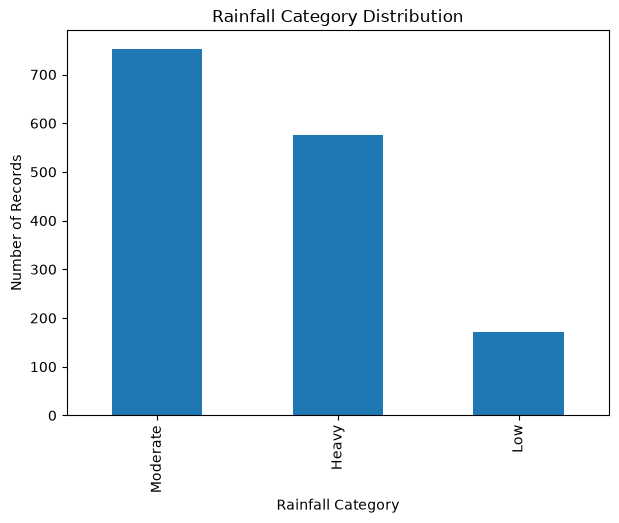

In [76]:
# Rainfall category visualization
plt.figure(figsize=(7,5))
df["Rainfall_Category"].value_counts().plot(kind="bar")
plt.xlabel("Rainfall Category")
plt.ylabel("Number of Records")
plt.title("Rainfall Category Distribution")
plt.show()

## Monthly Rainfall Analysis

In this step, the average rainfall is calculated for each month.

The `groupby()` function groups the data based on the `Month` column, and `mean()` calculates the average rainfall in millimeters for each month.

This helps us understand how rainfall varies across different months.

In [77]:
# Monthly rainfall analysis
monthly_rainfall = df.groupby("Month")["Rainfall_mm"].mean()
print(monthly_rainfall)

Month
1      98.900800
10    185.617500
11    128.322414
12    109.370992
2      87.919858
3      80.158197
4      88.602419
5     143.092623
6     266.167188
7     330.211200
8     309.599180
9     247.948387
Name: Rainfall_mm, dtype: float64


## Monthly Rainfall Visualization

A bar chart is used to visualize the average rainfall for each month.

The chart helps us compare the rainfall levels across different months and identify the months with higher or lower average rainfall.

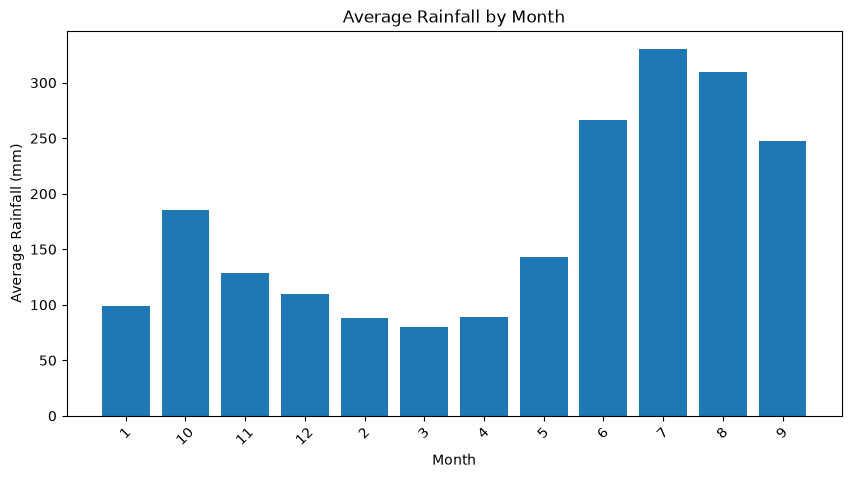

In [78]:
# Monthly rainfall visualization
plt.figure(figsize=(10,5))
plt.bar(monthly_rainfall.index, monthly_rainfall.values)
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.title("Average Rainfall by Month")
plt.xticks(rotation=45)
plt.show()

## Yearly Rainfall Analysis

In this step, the total rainfall is calculated for each year.

The `groupby()` function groups the data according to the `Year` column, and `sum()` calculates the total rainfall in millimeters for each year.

This helps us compare the total rainfall received in different years.

In [79]:
# Yearly rainfall analysis
yearly_rainfall = df.groupby("Year")["Rainfall_mm"].sum()
print(yearly_rainfall)

Year
2010    19705.0
2011    13871.8
2012    18534.9
2013    15137.1
2014    16959.6
2015    16135.4
2016    16334.0
2017    14765.7
2018    15369.5
2019    17319.2
2020    12716.0
2021    18642.1
2022    16555.5
2023    16457.8
2024    14220.4
2025    15608.2
Name: Rainfall_mm, dtype: float64


## Yearly Rainfall Visualization

A line chart is used to visualize the yearly rainfall trend.

The chart shows how the total rainfall changes from year to year. It helps us identify increasing or decreasing rainfall trends over time.

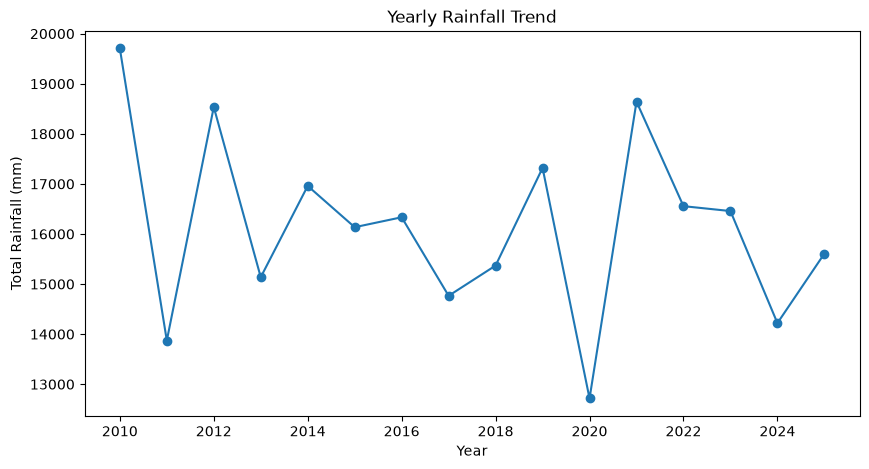

In [80]:
# Yearly rainfall visualization
plt.figure(figsize=(10,5))
plt.plot(yearly_rainfall.index, yearly_rainfall.values, marker="o")
plt.xlabel("Year")
plt.ylabel("Total Rainfall (mm)")
plt.title("Yearly Rainfall Trend")
plt.show()

## Defining Features and Target

In this step, the dataset is divided into **features (X)** and a **target (y)**.

- **Features (X)** are the input variables used by the machine learning model.
- **Target (y)** is the output that the model needs to predict.
- The target variable in this project is `Rainfall_Category`.

The selected features include year, month, temperature, humidity, wind speed, pressure, and rainfall.

In [81]:
# Define Features and Target

X = df[[
    "Year",
    "Month",
    "Temperature_C",
    "Humidity_Percent",
    "Wind_Speed_kmph",
    "Pressure_hPa",
    "Rainfall_mm"
]]

y = df["Rainfall_Category"]

print("Features:")
print(X.columns)
print("Target:", y.name)

Features:
Index(['Year', 'Month', 'Temperature_C', 'Humidity_Percent', 'Wind_Speed_kmph',
       'Pressure_hPa', 'Rainfall_mm'],
      dtype='str')
Target: Rainfall_Category


## Defining Features and Target

In this step, the dataset is divided into **features (X)** and a **target (y)**.

- **Features (X)** are the input variables used by the machine learning model.
- **Target (y)** is the output that the model needs to predict.
- The target variable in this project is `Rainfall_Category`.

The selected features include year, month, temperature, humidity, wind speed, pressure, and rainfall.

In [82]:
# Encode categorical features
X = pd.get_dummies(X, columns=["Month"], drop_first=False)
print(X.head())

   Year  Temperature_C  Humidity_Percent  Wind_Speed_kmph  Pressure_hPa  \
0  2024           25.0              71.0              6.7        1011.2   
1  2018           27.0              63.9             11.5        1011.2   
2  2015           23.9              82.1             11.2        1007.8   
3  2018           20.3              82.2             13.1        1006.5   
4  2023           22.9              98.0             14.8        1005.1   

   Rainfall_mm  Month_1  Month_10  Month_11  Month_12  Month_2  Month_3  \
0        114.5    False     False     False      True    False    False   
1         87.9     True     False     False     False    False    False   
2        206.4    False      True     False     False    False    False   
3        259.8    False     False     False     False    False    False   
4        339.2    False     False     False     False    False    False   

   Month_4  Month_5  Month_6  Month_7  Month_8  Month_9  
0    False    False    False    False   

## Encoding Target Variable

The target variable `Rainfall_Category` contains categorical values such as rainfall categories.

Machine learning algorithms require numerical values, so `LabelEncoder` is used to convert the categories into numerical labels.

The `classes_` attribute displays the original rainfall categories used by the model.

In [83]:
# Encode Target Variable

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Classes:", label_encoder.classes_)

Classes: ['Heavy' 'Low' 'Moderate']


## Importing Machine Learning Libraries

In this step, the required libraries for building and evaluating the machine learning model are imported.

- **train_test_split** – Splits the dataset into training and testing data.
- **RandomForestClassifier** – Machine learning algorithm used to classify rainfall categories.
- **accuracy_score** – Calculates the accuracy of the classification model.

In [84]:
# Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

## Splitting Training and Testing Data

In this step, the dataset is divided into two parts:

- **80% Training Data** – Used to train the machine learning model.
- **20% Testing Data** – Used to test the model's performance on unseen data.

The `random_state=42` ensures that the same data split is obtained each time the code is executed.

In [85]:
# Split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Training the Random Forest Model

In this step, the Random Forest model is trained using the training dataset.

The `fit()` function helps the model learn the relationship between the input features and the rainfall categories. After training, the model can be used to predict rainfall categories for new data.

In [86]:
# Train the model
model.fit(x_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",15
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

## Model Prediction

In this step, the trained Random Forest model is used to predict the rainfall categories for the testing data.

The `predict()` function takes the test features and generates the predicted rainfall categories. These predictions are stored in `y_pred` and will be compared with the actual values to calculate the model accuracy.

In [87]:
# Model Prediction
y_pred = model.predict(x_test)
print("Prediction Completed")

Prediction Completed


## Random Forest Classifier – Model Training and Accuracy

In this step, a **Random Forest Classifier** is created and trained using the training data.

The model uses multiple decision trees to classify the rainfall category.

### Model Parameters
- **n_estimators = 10** – Number of decision trees.
- **max_depth = 3** – Maximum depth of each tree.
- **min_samples_split = 15** – Minimum samples required to split a node.
- **min_samples_leaf = 8** – Minimum samples required in a leaf node.
- **random_state = 42** – Ensures reproducible results.

After training, the model predicts the rainfall categories for the test data. The `accuracy_score()` function is then used to calculate the model accuracy.

In [88]:
# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=10,
    max_depth=3,
    min_samples_split=15,
    min_samples_leaf=8,
    random_state=42
)

# Train the model
model.fit(x_train, y_train)

# Predict the test data
y_pred = model.predict(x_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

# Display accuracy
print("Algorithm Used: Random Forest Classifier")
print("Accuracy Percentage:", accuracy * 100)

Algorithm Used: Random Forest Classifier
Accuracy Percentage: 94.0


## Calculating and Visualizing the Confusion Matrix

A confusion matrix is used to evaluate the performance of the Random Forest Classifier.

It compares the **actual rainfall categories** with the **predicted rainfall categories**.

- **Rows** represent the actual rainfall categories.
- **Columns** represent the predicted rainfall categories.
- The diagonal values represent correctly predicted records.
- The other values represent incorrectly predicted records.

The confusion matrix helps us understand how well the model classifies each rainfall category.

In [89]:
# Calculate Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[106   0   9]
 [  0  28   9]
 [  0   0 148]]


## Confusion Matrix Visualization

A confusion matrix is used to evaluate the performance of the Random Forest Classifier.

It compares the **actual rainfall categories** with the **predicted rainfall categories**.

- **Rows** represent the actual categories.
- **Columns** represent the predicted categories.
- The values on the diagonal show the correctly classified records.
- Other values show incorrect predictions.

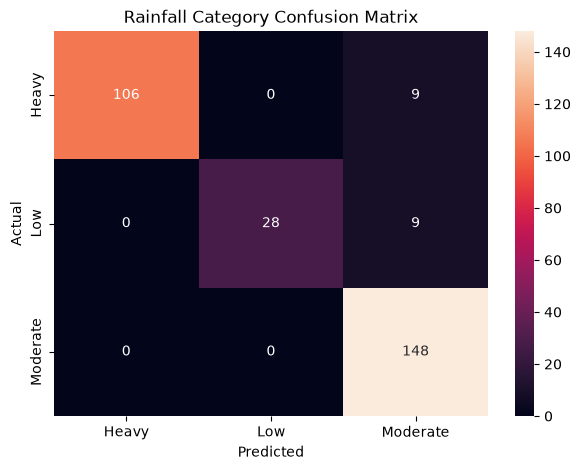

In [90]:
# Confusion Matrix Visualization
plt.figure(figsize=(7,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Rainfall Category Confusion Matrix")
plt.show()

# Feature Importance
importance = model.feature_importances_
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
})
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)
print(feature_importance)

In [91]:
# Calculate Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

             Feature  Importance
2   Humidity_Percent    0.289969
5        Rainfall_mm    0.279978
4       Pressure_hPa    0.179767
3    Wind_Speed_kmph    0.065078
14           Month_6    0.051722
16           Month_8    0.043683
1      Temperature_C    0.035956
17           Month_9    0.025679
11           Month_3    0.014918
7           Month_10    0.005430
8           Month_11    0.004845
0               Year    0.001412
10           Month_2    0.001211
9           Month_12    0.000353
6            Month_1    0.000000
12           Month_4    0.000000
13           Month_5    0.000000
15           Month_7    0.000000


## Saving the Trained Model

In this step, the trained Random Forest model is saved as a file using the `joblib` library.

The model is saved as **`rainfall_model.pkl`**.

This saved model can be loaded later and used to make rainfall predictions without training the model again.

In [92]:
# Save Model
import joblib
joblib.dump(model,"rainfall_model.pkl")
print("Model Saved Successfully")

Model Saved Successfully


## Rainfall Analysis – Project Completion

The rainfall data analysis and machine learning process is completed successfully.

The final output displays:

- **Model Accuracy** – Shows the accuracy of the Random Forest Classifier.
- **Algorithm** – Random Forest Classifier is used for rainfall category prediction.
- **Target** – `Rainfall_Category` is the variable predicted by the model.

This completes the Rainfall Data Analysis project.

In [93]:
# Rainfall Analysis Completed
print("===================================")
print("RAINFALL ANALYSIS COMPLETED")
print("===================================")
print("Model Accuracy:", round(accuracy * 100, 2), "%")
print("Algorithm: Random Forest Classifier")
print("Target: Rainfall Category")
print("===================================")

RAINFALL ANALYSIS COMPLETED
Model Accuracy: 94.0 %
Algorithm: Random Forest Classifier
Target: Rainfall Category


## Rainfall Data Search and Analysis

In this step, the user can search for a specific rainfall record by entering the **Year, Month, and Rainfall**.

The program checks the dataset for a matching record.

If a matching record is found, it displays:
- Temperature
- Humidity
- Wind Speed
- Pressure
- Rainfall
- Rainfall Category

It also displays the **average, maximum, and minimum rainfall** from the dataset.

If no matching record is found, the program displays a suitable message.

In [105]:
# Search Rainfall Record
df["Year"]=pd.to_numeric(df["Year"],errors="coerce")
df["Month"]=pd.to_numeric(df["Month"],errors="coerce")
year=int(input("Enter Year: "))
month=int(input("Enter Month (1-12): "))
result=df[(df["Year"]==year)&(df["Month"]==month)]
if len(result)>0:
    record=result.iloc[0]
    print("\n========== UNIQUE RAINFALL RECORD ==========")
    print("Year              :",record["Year"])
    print("Month             :",record["Month"])
    print("Rainfall          :",record["Rainfall_mm"],"mm")
    print("Temperature       :",record["Temperature_C"],"°C")
    print("Humidity          :",record["Humidity_Percent"],"%")
    print("Wind Speed        :",record["Wind_Speed_kmph"],"kmph")
    print("Pressure          :",record["Pressure_hPa"],"hPa")
    print("Rainfall Category :",record["Rainfall_Category"])
else:
    print("No matching record found")

Enter Year:  2019
Enter Month (1-12):  4



========== UNIQUE RAINFALL RECORD ==========
Year              : 2019
Month             : 4
Rainfall          : 61.6 mm
Temperature       : 27.1 °C
Humidity          : 59.5 %
Wind Speed        : 8.4 kmph
Pressure          : 1007.7 hPa
Rainfall Category : Low


## Future Enhancements

In the future, this project can be enhanced by using larger and more diverse rainfall datasets to improve prediction reliability. Real-time weather data can be integrated to provide updated rainfall information. Advanced machine learning and deep learning techniques can also be explored for better prediction performance. The system can be extended into a web or mobile application for easy rainfall analysis and prediction.



## Conclusion

This project successfully demonstrates the use of data preprocessing, exploratory data analysis, visualization, and machine learning for rainfall classification. The rainfall dataset was cleaned by handling missing values, duplicate records, and invalid values. Rainfall patterns were analyzed using different graphs, and a **Random Forest Classifier** was used to classify rainfall categories. The project provides a simple and effective way to analyze rainfall data and understand rainfall conditions.
